In [1]:
from src.benchmark import run_experiment

TRACKER_PARAMS = {
    "lost_track_buffer": 120,
    "track_activation_threshold": 0.35,
    "minimum_consecutive_frames": 1,
    "minimum_iou_threshold": 0.05,
    "high_conf_det_threshold": 0.5,
}

run_experiment(
    exp_name="QuickCheck_HOTA_YOLOv8s_INT8",
    model_path="weights/exported/yolov8s_visdrone_int8_800.engine",
    tracker_type="bytetrack_gmc",
    tracker_params=TRACKER_PARAMS,
    frames_dir="data/VisDrone2019-MOT-test-dev/sequences/uav0000249_00001_v",
    gt_path="data/VisDrone2019-MOT-test-dev/annotations/uav0000249_00001_v.txt",
    imgsz=800,
    conf_thres=0.35,
    iou_thres=0.45,
    gpu_preproc=True,
    results_csv="outputs/quick_check.csv",
)

Loading E:\Datasets\VisDroneTrackingAndDetecting\weights\exported\yolov8s_visdrone_int8_800.engine for TensorRT inference...


uav0000249_00001_v:   0%|          | 0/360 [00:00<?, ?frame/s]

[QuickCheck_HOTA_YOLOv8s_INT8] MOTA: 69.12% | IDF1: 81.95% | HOTA: 57.31% | ID Sw: 126 | FPS: 25.7 | Pure GPU: 2.72ms


{'Experiment': 'QuickCheck_HOTA_YOLOv8s_INT8',
 'Model': 'yolov8s_visdrone_int8_800.engine',
 'Tracker': 'bytetrack_gmc',
 'IMGSZ': 800,
 'MOTA (%)': 69.12,
 'IDF1 (%)': 81.95,
 'HOTA (%)': 57.31,
 'ID Switches': 126,
 'MT (>=80%)': 79,
 'ML (<=20%)': 39,
 'Matched (TP)': 5995,
 'Missed (FN)': 1835,
 'False Pos': 496,
 'Infer Latency (ms)': 11.47,
 'Track Latency (ms)': 7.0,
 'Total Latency (ms)': 38.89,
 'Jitter (ms)': 14.92,
 'FPS': 25.7,
 'Peak VRAM (MB)': 44.6,
 'Pure GPU (ms)': 2.72,
 'Disk Read (ms)': 20.42}

In [3]:
import gc
import torch
from src.benchmark import run_dataset_experiment

TRACKER_PARAMS = {
    "lost_track_buffer": 120,
    "track_activation_threshold": 0.35,
    "minimum_consecutive_frames": 1,
    "minimum_iou_threshold": 0.05,
    "high_conf_det_threshold": 0.5,
}

table1_runs = [
    ("01_YOLOv8s_COCO_Vanilla", "weights/yolov8s.pt", "bytetrack_vanilla"),
    ("02_YOLOv8s_VisDrone_FP32_Vanilla", "weights/yolov8s_visdrone.pt", "bytetrack_vanilla"),
    ("03_YOLOv8s_VisDrone_FP32_GMC", "weights/yolov8s_visdrone.pt", "bytetrack_gmc"),
]

for exp_name, model_path, tracker in table1_runs:
    gc.collect()
    torch.cuda.empty_cache()
    run_dataset_experiment(
        exp_name=exp_name,
        model_path=model_path,
        tracker_type=tracker,
        tracker_params=TRACKER_PARAMS,
        results_csv="outputs/table1_tracker_ablation.csv",
    )

01_YOLOv8s_COCO_Vanilla:   0%|          | 0/17 [00:00<?, ?seq/s]

[01_YOLOv8s_COCO_Vanilla] MOTA: 32.65% | IDF1: 45.87% | HOTA: 33.9% | ID Sw: 1075 | FPS: 19.5 | Pure GPU: 27.35ms


02_YOLOv8s_VisDrone_FP32_Vanilla:   0%|          | 0/17 [00:00<?, ?seq/s]

[02_YOLOv8s_VisDrone_FP32_Vanilla] MOTA: 47.72% | IDF1: 59.24% | HOTA: 40.8% | ID Sw: 2222 | FPS: 25.6 | Pure GPU: 8.79ms


03_YOLOv8s_VisDrone_FP32_GMC:   0%|          | 0/17 [00:00<?, ?seq/s]

[03_YOLOv8s_VisDrone_FP32_GMC] MOTA: 45.6% | IDF1: 60.44% | HOTA: 42.08% | ID Sw: 1393 | FPS: 23.7 | Pure GPU: 8.8ms


In [4]:
import gc
import torch
from src.benchmark import run_dataset_experiment

TRACKER_PARAMS = {
    "lost_track_buffer": 120,
    "track_activation_threshold": 0.35,
    "minimum_consecutive_frames": 1,
    "minimum_iou_threshold": 0.05,
    "high_conf_det_threshold": 0.5,
}

table2_runs = [
    ("YOLOv8s_COCO_GMC", "weights/yolov8s.pt"),
    ("YOLOv8s_VisDrone_FP32_GMC", "weights/yolov8s_visdrone.pt"),
    ("YOLO11n_COCO_GMC", "weights/yolo11n.pt"),
    ("YOLO11n_VisDrone_FP32_GMC", "weights/yolo11n_visdrone.pt"),
    ("YOLOv10s_COCO_GMC", "weights/yolov10s.pt"),
    ("YOLOv10s_VisDrone_FP32_GMC", "weights/yolov10s_visdrone.pt"),
    ("RTDETR_L_COCO_GMC", "weights/rtdetr-l.pt"),
    ("RTDETR_L_VisDrone_FP32_GMC", "weights/rtdetr_l_visdrone.pt"),
]

for exp_name, model_path in table2_runs:
    gc.collect()
    torch.cuda.empty_cache()
    run_dataset_experiment(
        exp_name=exp_name,
        model_path=model_path,
        tracker_type="bytetrack_gmc",
        tracker_params=TRACKER_PARAMS,
        results_csv="outputs/table2_architectures.csv",
    )

YOLOv8s_COCO_GMC:   0%|          | 0/17 [00:00<?, ?seq/s]

[YOLOv8s_COCO_GMC] MOTA: 30.86% | IDF1: 45.93% | HOTA: 34.62% | ID Sw: 642 | FPS: 24.2 | Pure GPU: 8.91ms


YOLOv8s_VisDrone_FP32_GMC:   0%|          | 0/17 [00:00<?, ?seq/s]

[YOLOv8s_VisDrone_FP32_GMC] MOTA: 45.6% | IDF1: 60.44% | HOTA: 42.08% | ID Sw: 1393 | FPS: 23.7 | Pure GPU: 8.8ms


YOLO11n_COCO_GMC:   0%|          | 0/17 [00:00<?, ?seq/s]

[YOLO11n_COCO_GMC] MOTA: 24.24% | IDF1: 38.23% | HOTA: 30.1% | ID Sw: 481 | FPS: 24.5 | Pure GPU: 8.78ms


... (6 outputs left out)

RTDETR_L_COCO_GMC:   0%|          | 0/17 [00:00<?, ?seq/s]

[RTDETR_L_COCO_GMC] MOTA: 13.57% | IDF1: 23.38% | HOTA: 18.42% | ID Sw: 320 | FPS: 14.9 | Pure GPU: 44.49ms


RTDETR_L_VisDrone_FP32_GMC:   0%|          | 0/17 [00:00<?, ?seq/s]

[RTDETR_L_VisDrone_FP32_GMC] MOTA: -173.71% | IDF1: 26.82% | HOTA: 22.69% | ID Sw: 26645 | FPS: 10.0 | Pure GPU: 41.97ms


In [5]:
import gc
import torch
from src.benchmark import run_dataset_experiment

TRACKER_PARAMS = {
    "lost_track_buffer": 120,
    "track_activation_threshold": 0.35,
    "minimum_consecutive_frames": 1,
    "minimum_iou_threshold": 0.05,
    "high_conf_det_threshold": 0.5,
}

table3_runs = [
    ("YOLOv8s_FP32", "weights/yolov8s_visdrone.pt"),
    ("YOLOv8s_TRT_FP16", "weights/exported/yolov8s_visdrone_fp16_800.engine"),
    ("YOLOv8s_TRT_INT8", "weights/exported/yolov8s_visdrone_int8_800.engine"),
    ("YOLO11n_FP32", "weights/yolo11n_visdrone.pt"),
    ("YOLO11n_TRT_FP16", "weights/exported/yolo11n_visdrone_fp16_800.engine"),
    ("YOLO11n_TRT_INT8", "weights/exported/yolo11n_visdrone_int8_800.engine"),
    ("YOLOv10s_FP32", "weights/yolov10s_visdrone.pt"),
    ("YOLOv10s_TRT_FP16", "weights/exported/yolov10s_visdrone_fp16_800.engine"),
    ("YOLOv10s_TRT_INT8", "weights/exported/yolov10s_visdrone_int8_800.engine"),
    ("RTDETR_L_FP32", "weights/rtdetr_l_visdrone.pt"),
    ("RTDETR_L_TRT_FP16", "weights/exported/rtdetr_l_visdrone_fp16_800.engine"),
    ("RTDETR_L_TRT_INT8", "weights/exported/rtdetr_l_visdrone_int8_800.engine"),
]

for exp_name, model_path in table3_runs:
    gc.collect()
    torch.cuda.empty_cache()
    run_dataset_experiment(
        exp_name=exp_name,
        model_path=model_path,
        tracker_type="bytetrack_gmc",
        tracker_params=TRACKER_PARAMS,
        results_csv="outputs/table3_tensorrt.csv",
    )

YOLOv8s_FP32:   0%|          | 0/17 [00:00<?, ?seq/s]

[YOLOv8s_FP32] MOTA: 45.6% | IDF1: 60.44% | HOTA: 42.08% | ID Sw: 1393 | FPS: 23.0 | Pure GPU: 8.86ms
Loading E:\Datasets\VisDroneTrackingAndDetecting\weights\exported\yolov8s_visdrone_fp16_800.engine for TensorRT inference...


YOLOv8s_TRT_FP16:   0%|          | 0/17 [00:00<?, ?seq/s]

[YOLOv8s_TRT_FP16] MOTA: 45.61% | IDF1: 60.42% | HOTA: 42.13% | ID Sw: 1403 | FPS: 23.7 | Pure GPU: 2.72ms
Loading E:\Datasets\VisDroneTrackingAndDetecting\weights\exported\yolov8s_visdrone_int8_800.engine for TensorRT inference...


YOLOv8s_TRT_INT8:   0%|          | 0/17 [00:00<?, ?seq/s]

[YOLOv8s_TRT_INT8] MOTA: 46.4% | IDF1: 61.13% | HOTA: 42.12% | ID Sw: 1514 | FPS: 23.9 | Pure GPU: 3.01ms


... (14 outputs left out)

RTDETR_L_TRT_FP16:   0%|          | 0/17 [00:00<?, ?seq/s]

[RTDETR_L_TRT_FP16] MOTA: -174.06% | IDF1: 27.08% | HOTA: 22.82% | ID Sw: 26809 | FPS: 12.0 | Pure GPU: 7.51ms
Loading E:\Datasets\VisDroneTrackingAndDetecting\weights\exported\rtdetr_l_visdrone_int8_800.engine for TensorRT inference...


RTDETR_L_TRT_INT8:   0%|          | 0/17 [00:00<?, ?seq/s]

[RTDETR_L_TRT_INT8] MOTA: -364.89% | IDF1: 9.63% | HOTA: 5.61% | ID Sw: 69586 | FPS: 8.1 | Pure GPU: 5.34ms


In [2]:
import gc
import torch
from src.benchmark import run_dataset_experiment

TRACKER_PARAMS = {
    "lost_track_buffer": 120,
    "track_activation_threshold": 0.35,
    "minimum_consecutive_frames": 1,
    "minimum_iou_threshold": 0.05,
    "high_conf_det_threshold": 0.5,
}

for exp_name, model_path in [
    ("RTDETR_L_COCO_GMC", "weights/rtdetr-l.pt"),
    ("RTDETR_L_VisDrone_FP32_GMC", "weights/rtdetr_l_visdrone.pt"),
]:
    gc.collect()
    torch.cuda.empty_cache()
    run_dataset_experiment(
        exp_name=exp_name,
        model_path=model_path,
        tracker_type="bytetrack_gmc",
        tracker_params=TRACKER_PARAMS,
        results_csv="outputs/table2_architectures.csv",
    )

for exp_name, model_path in [
    ("RTDETR_L_FP32", "weights/rtdetr_l_visdrone.pt"),
    ("RTDETR_L_TRT_FP16", "weights/exported/rtdetr_l_visdrone_fp16_800.engine"),
    ("RTDETR_L_TRT_INT8", "weights/exported/rtdetr_l_visdrone_int8_800.engine"),
]:
    gc.collect()
    torch.cuda.empty_cache()
    run_dataset_experiment(
        exp_name=exp_name,
        model_path=model_path,
        tracker_type="bytetrack_gmc",
        tracker_params=TRACKER_PARAMS,
        results_csv="outputs/table3_tensorrt.csv",
    )

RTDETR_L_COCO_GMC:   0%|          | 0/17 [00:00<?, ?seq/s]

[RTDETR_L_COCO_GMC] MOTA: 40.46% | IDF1: 55.37% | HOTA: 38.3% | ID Sw: 1843 | FPS: 14.6 | Pure GPU: 40.34ms


RTDETR_L_VisDrone_FP32_GMC:   0%|          | 0/17 [00:00<?, ?seq/s]

[RTDETR_L_VisDrone_FP32_GMC] MOTA: 52.23% | IDF1: 62.01% | HOTA: 40.56% | ID Sw: 6407 | FPS: 14.4 | Pure GPU: 39.54ms


RTDETR_L_FP32:   0%|          | 0/17 [00:00<?, ?seq/s]

[RTDETR_L_FP32] MOTA: 52.23% | IDF1: 62.01% | HOTA: 40.56% | ID Sw: 6407 | FPS: 14.4 | Pure GPU: 39.57ms
Loading E:\Datasets\VisDroneTrackingAndDetecting\weights\exported\rtdetr_l_visdrone_fp16_800.engine for TensorRT inference...


RTDETR_L_TRT_FP16:   0%|          | 0/17 [00:00<?, ?seq/s]

[RTDETR_L_TRT_FP16] MOTA: 52.17% | IDF1: 61.95% | HOTA: 40.46% | ID Sw: 6632 | FPS: 22.1 | Pure GPU: 7.47ms
Loading E:\Datasets\VisDroneTrackingAndDetecting\weights\exported\rtdetr_l_visdrone_int8_800.engine for TensorRT inference...


RTDETR_L_TRT_INT8:   0%|          | 0/17 [00:00<?, ?seq/s]

[RTDETR_L_TRT_INT8] MOTA: 0.0% | IDF1: 0.0% | HOTA: 0.0% | ID Sw: 0 | FPS: 26.8 | Pure GPU: 5.37ms


E:\Datasets\VisDroneTrackingAndDetecting\src\metrics.py:139: RuntimeWarning: invalid value encountered in divide
  assa = np.where(tp > 0, assa_sum / tp, 0.0)


In [16]:
import gc
import torch
from src.benchmark import run_dataset_experiment

TRACKER_PARAMS = {
    "lost_track_buffer": 120,
    "track_activation_threshold": 0.35,
    "minimum_consecutive_frames": 1,
    "minimum_iou_threshold": 0.05,
    "high_conf_det_threshold": 0.5,
}

run_dataset_experiment(
    exp_name="RTDETR_L_TRT_INT8",
    model_path="weights/exported/rtdetr_l_visdrone_int8_800.engine",
    tracker_type="bytetrack_gmc",
    tracker_params=TRACKER_PARAMS,
    results_csv="outputs/table3_tensorrt.csv",
)

Loading E:\Datasets\VisDroneTrackingAndDetecting\weights\exported\rtdetr_l_visdrone_int8_800.engine for TensorRT inference...


RTDETR_L_TRT_INT8:   0%|          | 0/17 [00:00<?, ?seq/s]

[RTDETR_L_TRT_INT8] MOTA: 0.0% | IDF1: 0.0% | HOTA: 0.0% | ID Sw: 0 | FPS: 25.2 | Pure GPU: 5.3ms


{'Experiment': 'RTDETR_L_TRT_INT8',
 'Model': 'rtdetr_l_visdrone_int8_800.engine',
 'Tracker': 'bytetrack_gmc',
 'IMGSZ': 800,
 'MOTA (%)': 0.0,
 'IDF1 (%)': 0.0,
 'HOTA (%)': 0.0,
 'ID Switches': 0,
 'MT (>=80%)': 0,
 'ML (<=20%)': 2196,
 'Matched (TP)': 0,
 'Missed (FN)': 293087,
 'False Pos': 0,
 'Infer Latency (ms)': 17.69,
 'Track Latency (ms)': 3.28,
 'Total Latency (ms)': 39.68,
 'Jitter (ms)': 16.83,
 'FPS': 25.2,
 'Peak VRAM (MB)': 65.0,
 'Pure GPU (ms)': 5.3,
 'Disk Read (ms)': 18.71}

In [7]:
import cv2
import numpy as np
import torch
from ultralytics import YOLO

m = YOLO("weights/exported/rtdetr_l_visdrone_int8_800.engine", task="detect")
_ = m.predict(np.zeros((800, 800, 3), dtype=np.uint8), imgsz=800, verbose=False)

img = cv2.imread("data/VisDrone2019-MOT-test-dev/sequences/uav0000249_00001_v/0000001.jpg")
img_rz = cv2.resize(img, (800, 800))
tensor = torch.from_numpy(img_rz).cuda().permute(2, 0, 1).flip(0).unsqueeze(0).float().div_(255.0)

with torch.inference_mode():
    out = m.predictor.model.forward(tensor)

preds = (out[0] if isinstance(out, (list, tuple)) else out).squeeze(0)
print("Max confidence in INT8:", float(preds[:, 4].max()))
print("Top-10 confidences:", torch.topk(preds[:, 4], 10).values.cpu().numpy().round(3))

Loading weights/exported/rtdetr_l_visdrone_int8_800.engine for TensorRT inference...
Max confidence in INT8: 0.14453125
Top-10 confidences: [      0.145       0.123       0.116       0.116       0.108       0.108       0.108       0.108       0.108       0.101]


In [12]:
import pandas as pd

tables = {
    "Table 1: Domain Adaptation & GMC Ablation": "outputs/table1_tracker_ablation.csv",
    "Table 2: Architectures Comparison (COCO vs VisDrone)": "outputs/table2_architectures.csv",
    "Table 3: TensorRT Optimization (FP32 vs FP16 vs INT8)": "outputs/table3_tensorrt.csv",
}

cols_to_show = [
    "Experiment", "MOTA (%)", "IDF1 (%)", "HOTA (%)", "ID Switches",
    "Pure GPU (ms)", "Infer Latency (ms)", "Total Latency (ms)", "FPS", "Peak VRAM (MB)"
]

for title, path in tables.items():
    df = pd.read_csv(path)
    available_cols = [c for c in cols_to_show if c in df.columns]
    sub = df[available_cols]

    print(f"\n{'=' * 70}\n{title}\n{'=' * 70}")
    display(sub)



Table 1: Domain Adaptation & GMC Ablation


,Experiment,MOTA (%),IDF1 (%),HOTA (%),ID Switches,Pure GPU (ms),Infer Latency (ms),Total Latency (ms),FPS,Peak VRAM (MB)
0,01_YOLOv8s_COCO_Vanilla,32.65,45.87,33.90,1075,27.35,22.20,51.21,19.5,265.5
1,02_YOLOv8s_VisDrone_FP32_Vanilla,47.72,59.24,40.80,2222,8.79,18.43,39.05,25.6,265.3
2,03_YOLOv8s_VisDrone_FP32_GMC,45.60,60.44,42.08,1393,8.80,19.13,42.28,23.7,265.3



Table 2: Architectures Comparison (COCO vs VisDrone)


,Experiment,MOTA (%),IDF1 (%),HOTA (%),ID Switches,Pure GPU (ms),Infer Latency (ms),Total Latency (ms),FPS,Peak VRAM (MB)
0,YOLOv8s_COCO_GMC,30.86,45.93,34.62,642,8.91,18.87,41.39,24.2,265.5
1,YOLOv8s_VisDrone_FP32_GMC,45.60,60.44,42.08,1393,8.80,19.09,42.20,23.7,265.3
2,YOLO11n_COCO_GMC,24.24,38.23,30.10,481,8.78,18.52,40.78,24.5,230.2
3,YOLO11n_VisDrone_FP32_GMC,32.80,48.22,37.34,700,8.64,18.59,41.21,24.3,230.1
4,YOLOv10s_COCO_GMC,29.04,43.79,34.08,632,8.68,19.00,41.75,24.0,270.2
5,YOLOv10s_VisDrone_FP32_GMC,42.60,57.50,41.78,1188,8.71,19.26,42.45,23.6,269.9
6,RTDETR_L_COCO_GMC,40.46,55.37,38.30,1843,40.34,45.37,68.65,14.6,418.2
7,RTDETR_L_VisDrone_FP32_GMC,52.23,62.01,40.56,6407,39.54,44.97,69.41,14.4,414.6



Table 3: TensorRT Optimization (FP32 vs FP16 vs INT8)


,Experiment,MOTA (%),IDF1 (%),HOTA (%),ID Switches,Pure GPU (ms),Infer Latency (ms),Total Latency (ms),FPS,Peak VRAM (MB)
0,YOLOv8s_FP32,45.60,60.44,42.08,1393,8.86,19.69,43.45,23.0,297.3
1,YOLOv8s_TRT_FP16,45.61,60.42,42.13,1403,2.72,18.90,42.27,23.7,217.7
2,YOLOv8s_TRT_INT8,46.40,61.13,42.12,1514,3.01,18.32,41.82,23.9,217.7
3,YOLO11n_FP32,32.80,48.22,37.34,700,8.67,18.98,41.84,23.9,230.1
4,YOLO11n_TRT_FP16,32.92,48.29,37.36,693,2.55,17.06,39.85,25.1,217.7
5,YOLO11n_TRT_INT8,33.24,48.66,37.30,782,2.16,17.82,41.05,24.4,217.7
6,YOLOv10s_FP32,42.60,57.50,41.78,1188,8.62,19.07,42.21,23.7,269.9
7,YOLOv10s_TRT_FP16,42.55,57.41,41.69,1252,2.82,18.35,41.17,24.3,217.7
8,YOLOv10s_TRT_INT8,42.70,57.41,41.47,1277,3.06,17.82,40.72,24.6,217.7
9,RTDETR_L_FP32,52.23,62.01,40.56,6407,39.57,45.01,69.46,14.4,414.6


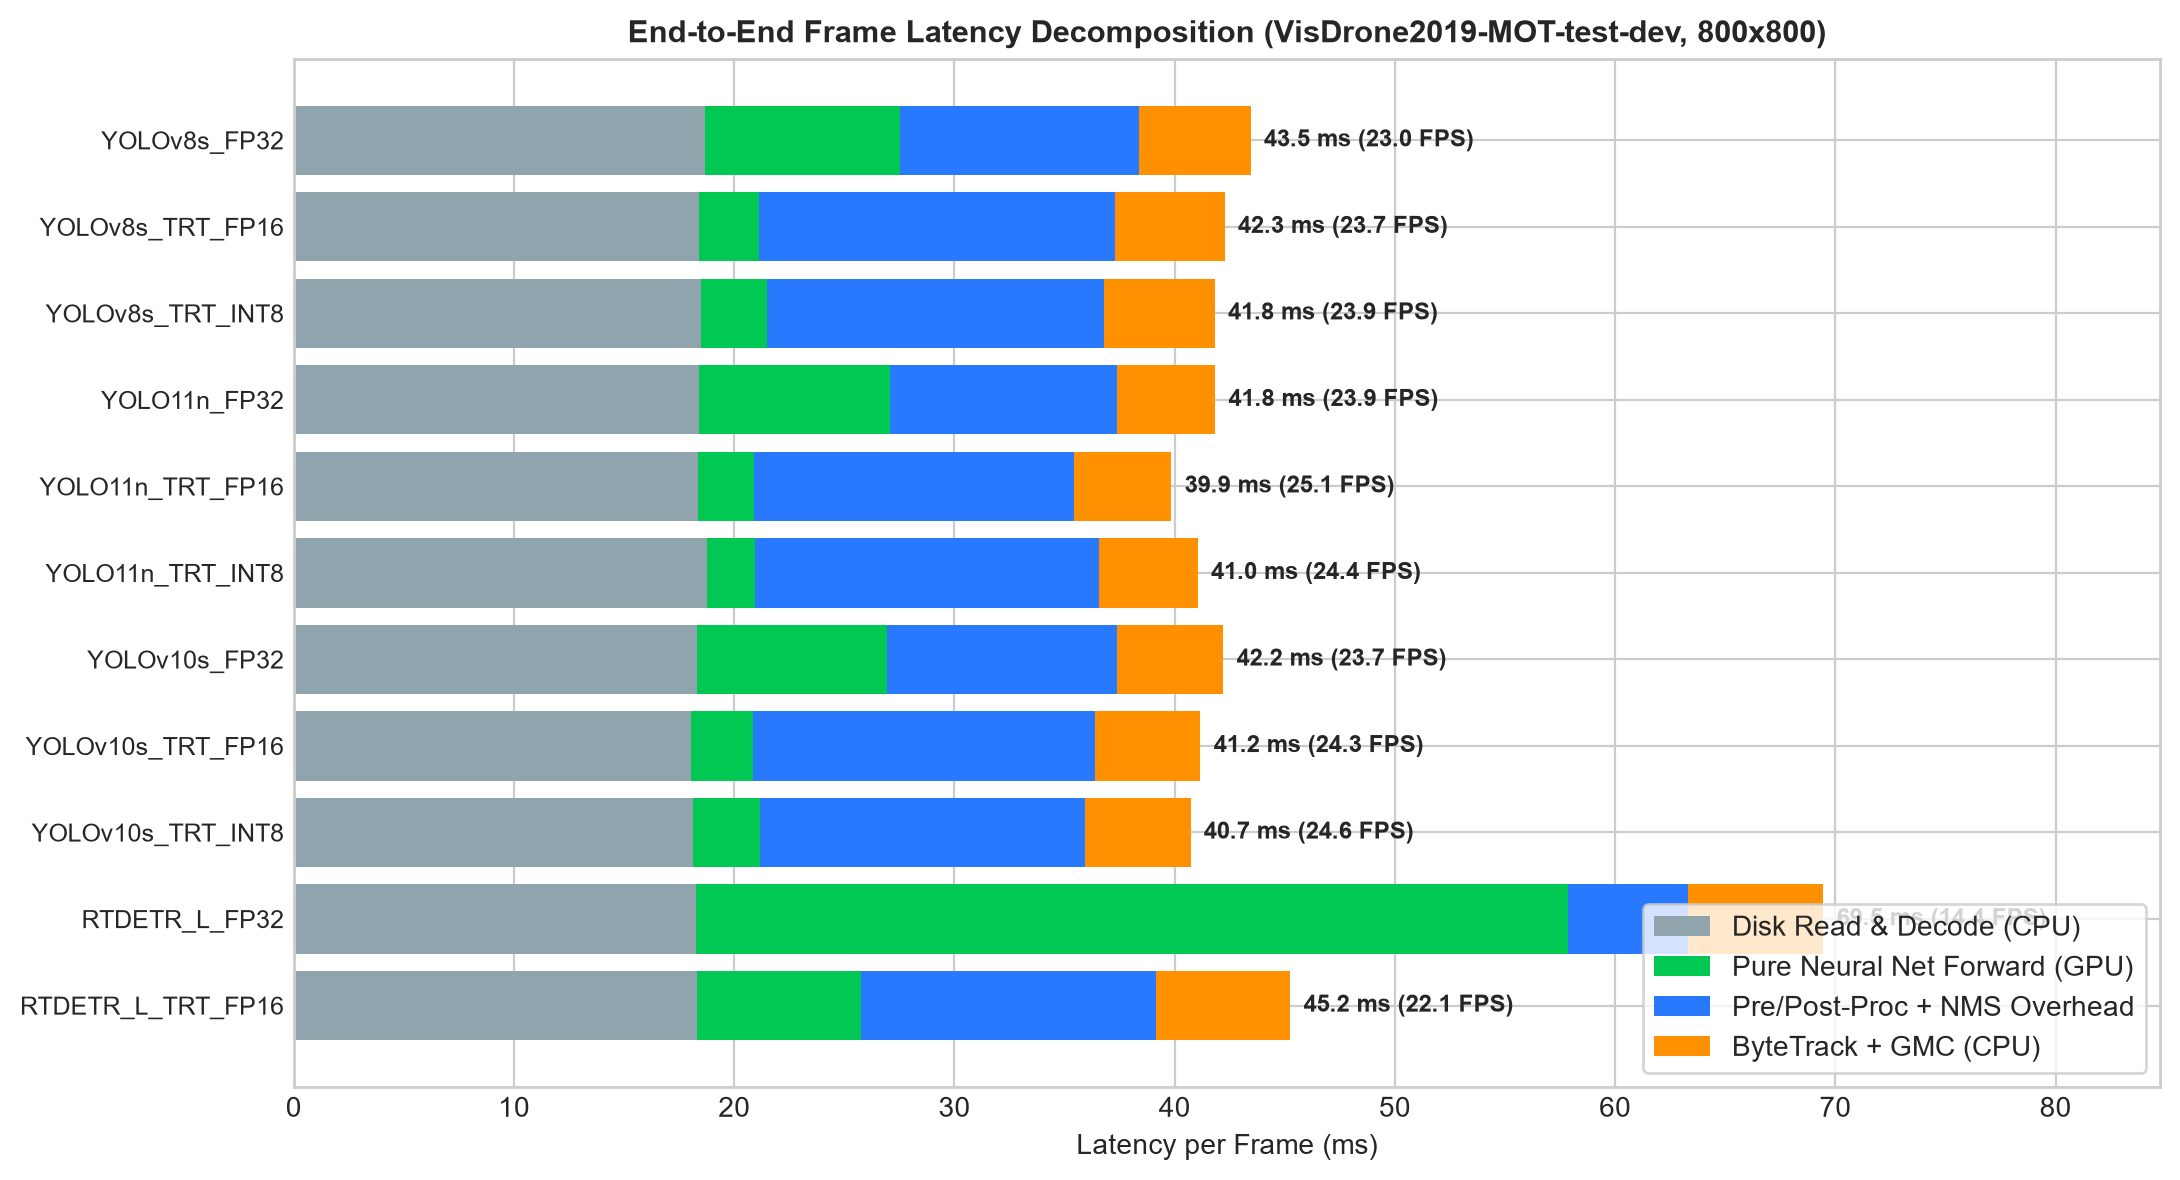

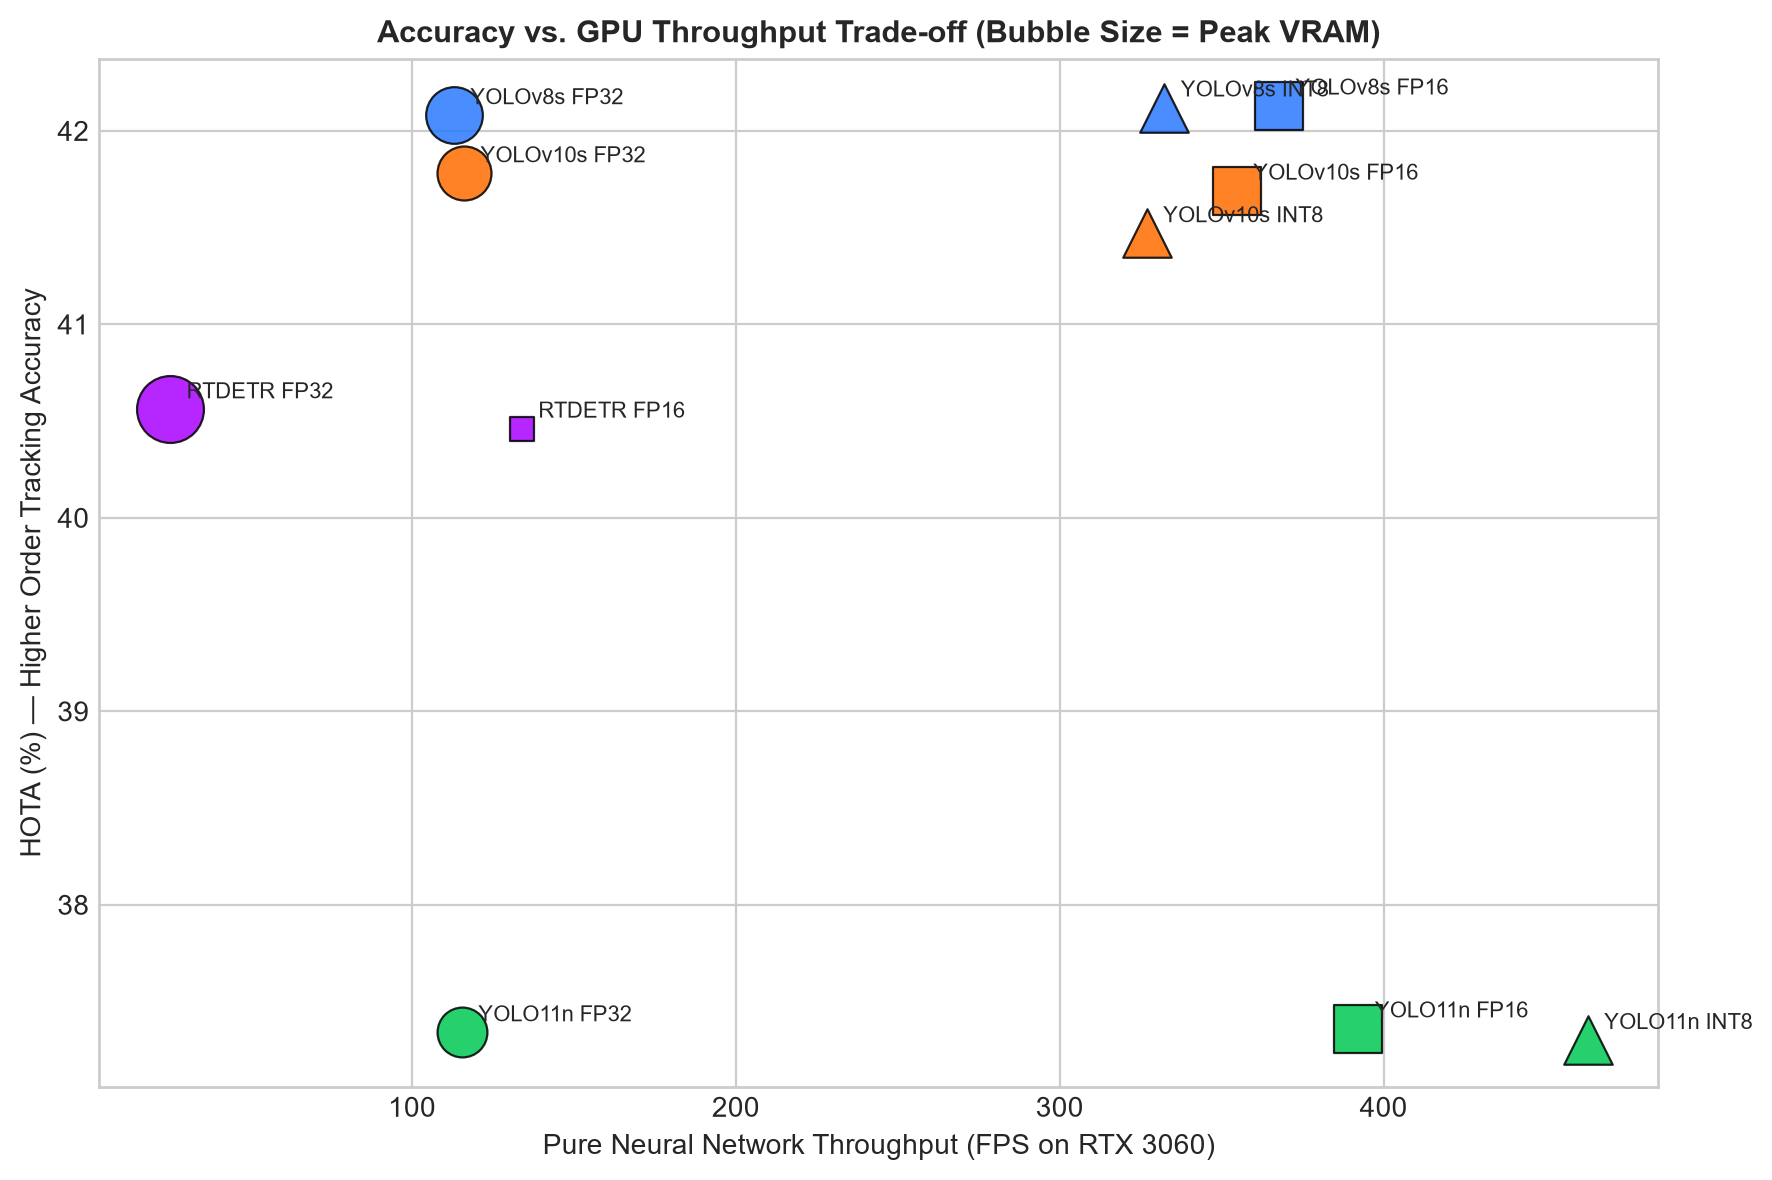

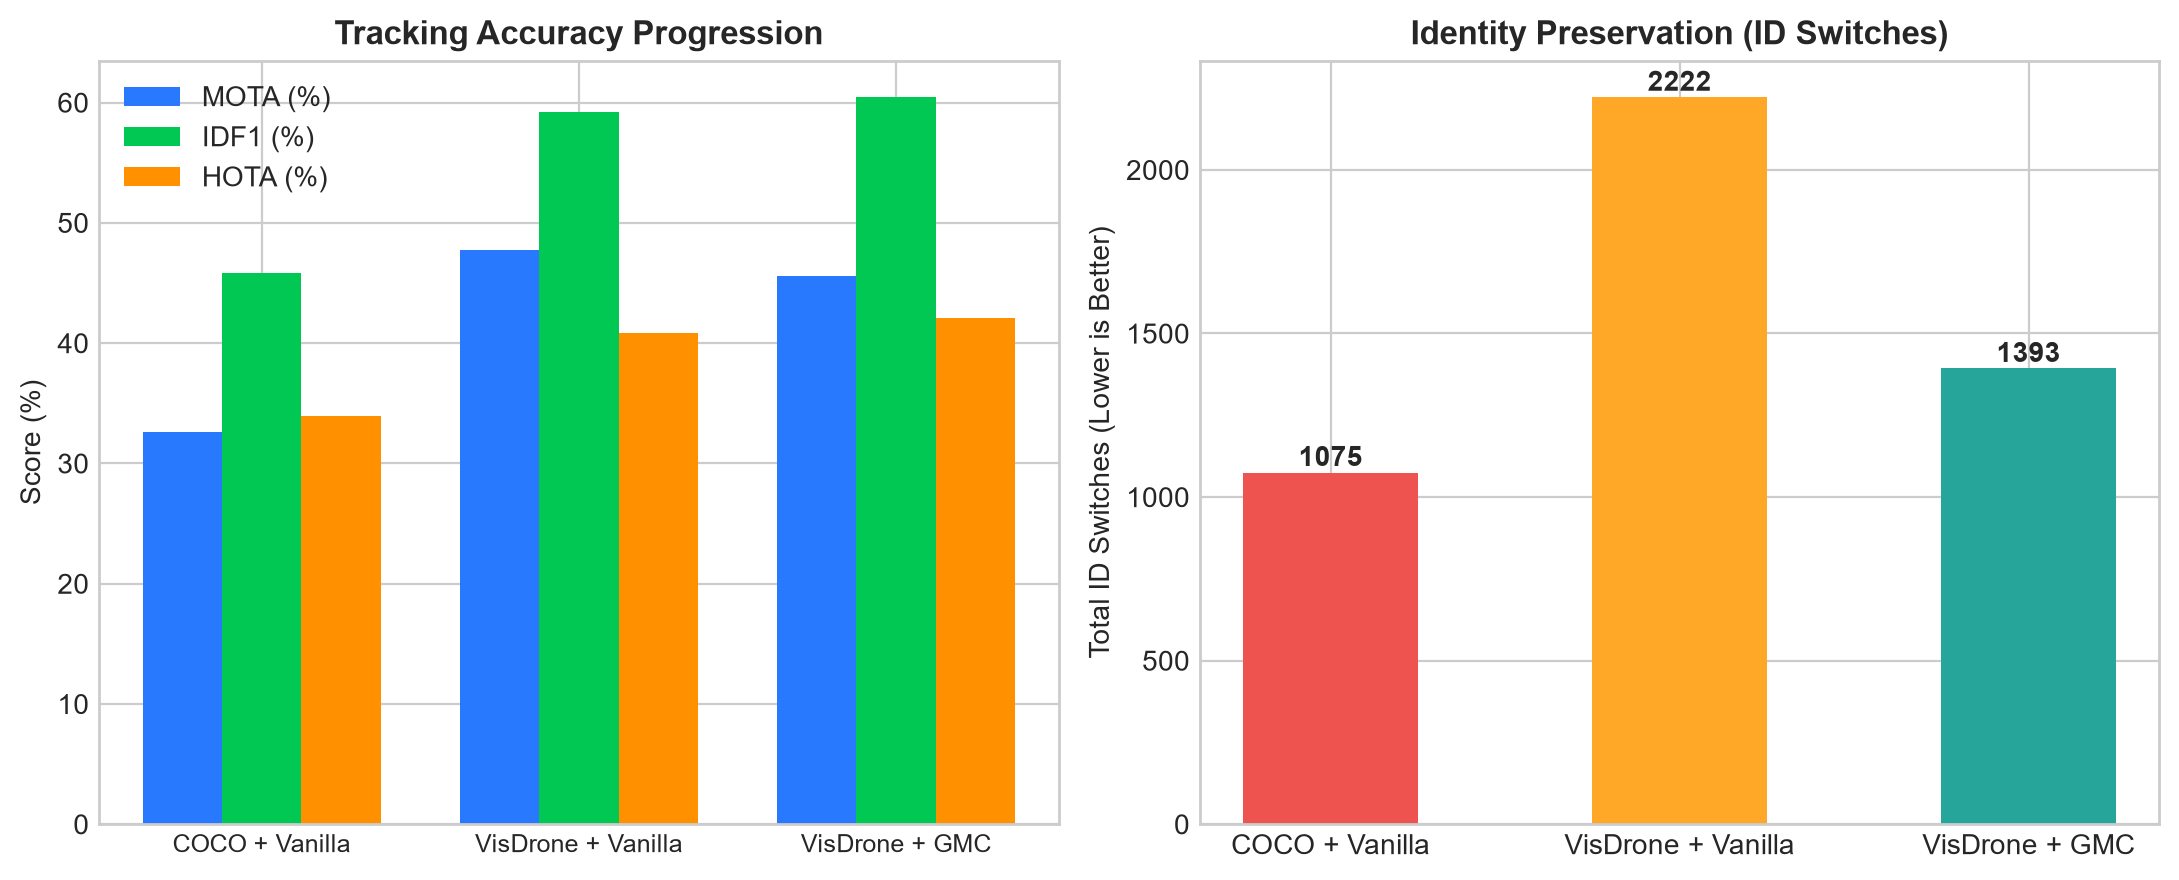

In [13]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

os.makedirs("outputs/figures", exist_ok=True)
plt.style.use("seaborn-v0_8-whitegrid")

t1 = pd.read_csv("outputs/table1_tracker_ablation.csv")
t3 = pd.read_csv("outputs/table3_tensorrt.csv")

# --- 1. Latency Breakdown (Stacked Bar Chart) ---
fig, ax = plt.subplots(figsize=(11, 6), dpi=200)
labels = t3["Experiment"]
disk = t3["Disk Read (ms)"]
pure_gpu = t3["Pure GPU (ms)"]
overhead = np.maximum(0.0, t3["Infer Latency (ms)"] - t3["Pure GPU (ms)"])
track = t3["Track Latency (ms)"]

y = np.arange(len(labels))
ax.barh(y, disk, label="Disk Read & Decode (CPU)", color="#90A4AE")
ax.barh(y, pure_gpu, left=disk, label="Pure Neural Net Forward (GPU)", color="#00C853")
ax.barh(y, overhead, left=disk + pure_gpu, label="Pre/Post-Proc + NMS Overhead", color="#2979FF")
ax.barh(y, track, left=disk + pure_gpu + overhead, label="ByteTrack + GMC (CPU)", color="#FF9100")

for i, total in enumerate(t3["Total Latency (ms)"]):
    ax.text(total + 0.6, y[i], f"{total:.1f} ms ({t3['FPS'].iloc[i]:.1f} FPS)", va="center", fontsize=8.5, fontweight="bold")

ax.set_yticks(y)
ax.set_yticklabels(labels, fontsize=9)
ax.invert_yaxis()
ax.set_xlabel("Latency per Frame (ms)", fontsize=10)
ax.set_title("End-to-End Frame Latency Decomposition (VisDrone2019-MOT-test-dev, 800x800)", fontsize=11, fontweight="bold")
ax.set_xlim(0, t3["Total Latency (ms)"].max() * 1.22)
ax.legend(loc="lower right", frameon=True)
plt.tight_layout()
plt.savefig("outputs/figures/01_latency_breakdown.png")
plt.show()

# --- 2. Pareto Frontier: HOTA (%) vs Pure GPU Speed (FPS) ---
fig, ax = plt.subplots(figsize=(9, 6), dpi=200)
colors = {"YOLOv8s": "#2979FF", "YOLO11n": "#00C853", "YOLOv10s": "#FF6D00", "RTDETR": "#AA00FF"}
markers = {"FP32": "o", "FP16": "s", "INT8": "^"}

for _, row in t3.iterrows():
    exp = row["Experiment"]
    arch = next((k for k in colors if k in exp), "YOLOv8s")
    prec = "INT8" if "INT8" in exp else ("FP16" if "FP16" in exp else "FP32")
    gpu_fps = 1000.0 / row["Pure GPU (ms)"] if row["Pure GPU (ms)"] > 0 else row["FPS"]

    ax.scatter(
        gpu_fps, row["HOTA (%)"],
        s=max(60, row["Peak VRAM (MB)"] * 1.4),
        color=colors[arch], marker=markers[prec], alpha=0.85, edgecolors="black", linewidth=0.8
    )
    ax.annotate(
        f"{arch} {prec}", (gpu_fps, row["HOTA (%)"]),
        textcoords="offset points", xytext=(6, 4), fontsize=8
    )

ax.set_xlabel("Pure Neural Network Throughput (FPS on RTX 3060)", fontsize=10)
ax.set_ylabel("HOTA (%) — Higher Order Tracking Accuracy", fontsize=10)
ax.set_title("Accuracy vs. GPU Throughput Trade-off (Bubble Size = Peak VRAM)", fontsize=11, fontweight="bold")
plt.tight_layout()
plt.savefig("outputs/figures/02_pareto_hota_vs_speed.png")
plt.show()

# --- 3. Impact of Fine-Tuning & GMC (Table 1) ---
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.5), dpi=200)
x = np.arange(len(t1))
w = 0.25

ax1.bar(x - w, t1["MOTA (%)"], width=w, label="MOTA (%)", color="#2979FF")
ax1.bar(x, t1["IDF1 (%)"], width=w, label="IDF1 (%)", color="#00C853")
ax1.bar(x + w, t1["HOTA (%)"], width=w, label="HOTA (%)", color="#FF9100")
ax1.set_xticks(x)
ax1.set_xticklabels(["COCO + Vanilla", "VisDrone + Vanilla", "VisDrone + GMC"], fontsize=9)
ax1.set_ylabel("Score (%)")
ax1.set_title("Tracking Accuracy Progression", fontweight="bold")
ax1.legend()

bars = ax2.bar(["COCO + Vanilla", "VisDrone + Vanilla", "VisDrone + GMC"], t1["ID Switches"], color=["#EF5350", "#FFA726", "#26A69A"], width=0.5)
for b in bars:
    ax2.text(b.get_x() + b.get_width() / 2, b.get_height() + 20, f"{int(b.get_height())}", ha="center", fontweight="bold")
ax2.set_ylabel("Total ID Switches (Lower is Better)")
ax2.set_title("Identity Preservation (ID Switches)", fontweight="bold")

plt.tight_layout()
plt.savefig("outputs/figures/03_ablation_gmc_impact.png")
plt.show()

In [15]:
import os
import cv2
from src.visualizer import run_visualization

SEQ_NAME = "uav0000249_00001_v"
GT_PATH = f"data/VisDrone2019-MOT-test-dev/annotations/{SEQ_NAME}.txt"
VIDEO_MP4 = f"data/videos/{SEQ_NAME}.mp4"

TRACKER_PARAMS = {
    "lost_track_buffer": 120,
    "track_activation_threshold": 0.35,
    "minimum_consecutive_frames": 1,
    "minimum_iou_threshold": 0.05,
    "high_conf_det_threshold": 0.5,
}

videos_to_render = [
    ("01_baseline_coco_vanilla.mp4", "weights/yolov8s.pt", "bytetrack_vanilla", False),
    ("02_yolov8s_int8_gmc.mp4", "weights/exported/yolov8s_visdrone_int8_800.engine", "bytetrack_gmc", True),
    ("03_yolo11n_int8_gmc.mp4", "weights/exported/yolo11n_visdrone_int8_800.engine", "bytetrack_gmc", True),
    ("04_yolo10s_int8_gmc.mp4", "weights/exported/yolo10s_visdrone_int8_800.engine", "bytetrack_gmc", True),
    ("05_rtdetr_l_fp16_gmc.mp4", "weights/exported/rtdetr_l_visdrone_fp16_800.engine", "bytetrack_gmc", True),
]

for out_name, weights, tracker, draw_gmc in videos_to_render:
    run_visualization(
        model_path=weights,
        video_path=VIDEO_MP4,
        output_path=f"outputs/videos/{out_name}",
        tracker_type=tracker,
        tracker_params=TRACKER_PARAMS,
        gt_path=GT_PATH,
        show_traces=False,
        show_gmc_flow=draw_gmc,
        imgsz=800,
        conf_thres=0.35,
        iou_thres=0.45,
    )

Starting visualization. Model: yolov8s.pt | Tracker: bytetrack_vanilla


Rendering video:   0%|          | 0/360 [00:00<?, ?it/s]

Done! Video saved to: E:\Datasets\VisDroneTrackingAndDetecting\outputs\videos\01_baseline_coco_vanilla.mp4
Unique objects (Track IDs): 161
Starting visualization. Model: yolov8s_visdrone_int8_800.engine | Tracker: bytetrack_gmc
Loading E:\Datasets\VisDroneTrackingAndDetecting\weights\exported\yolov8s_visdrone_int8_800.engine for TensorRT inference...


Rendering video:   0%|          | 0/360 [00:00<?, ?it/s]

Done! Video saved to: E:\Datasets\VisDroneTrackingAndDetecting\outputs\videos\02_yolov8s_int8_gmc.mp4
Unique objects (Track IDs): 141
Starting visualization. Model: yolo11n_visdrone_int8_800.engine | Tracker: bytetrack_gmc
Loading E:\Datasets\VisDroneTrackingAndDetecting\weights\exported\yolo11n_visdrone_int8_800.engine for TensorRT inference...


Rendering video:   0%|          | 0/360 [00:00<?, ?it/s]

Done! Video saved to: E:\Datasets\VisDroneTrackingAndDetecting\outputs\videos\03_yolo11n_int8_gmc.mp4
Unique objects (Track IDs): 125
Starting visualization. Model: yolov10s_visdrone_int8_800.engine | Tracker: bytetrack_gmc
Loading E:\Datasets\VisDroneTrackingAndDetecting\weights\exported\yolov10s_visdrone_int8_800.engine for TensorRT inference...


Rendering video:   0%|          | 0/360 [00:00<?, ?it/s]

Done! Video saved to: E:\Datasets\VisDroneTrackingAndDetecting\outputs\videos\04_yolo10s_int8_gmc.mp4
Unique objects (Track IDs): 152
Starting visualization. Model: rtdetr_l_visdrone_fp16_800.engine | Tracker: bytetrack_gmc
Loading E:\Datasets\VisDroneTrackingAndDetecting\weights\exported\rtdetr_l_visdrone_fp16_800.engine for TensorRT inference...


Rendering video:   0%|          | 0/360 [00:00<?, ?it/s]

Done! Video saved to: E:\Datasets\VisDroneTrackingAndDetecting\outputs\videos\05_rtdetr_l_fp16_gmc.mp4
Unique objects (Track IDs): 247
